**Import the important libraries that will be used frequently**

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

**Collecting data after it was scattered and reading it
delim_whitespace as cutting tool and header to give columns an index start from zero**

In [ ]:
df = pd.read_csv('/content/DataClass.txt' , delim_whitespace = True , header = None)
df

<ipython-input-250-4acfc6db8a9e>:1: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv('/content/DataClass.txt' , delim_whitespace = True , header = None)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
0,95,48,83,178,72,10,162,42,20,159,176,379,184,70,6,16,187,197,van
1,91,41,84,141,57,9,149,45,19,143,170,330,158,72,9,14,189,199,van
2,104,50,106,209,66,10,207,32,23,158,223,635,220,73,14,9,188,196,saab
3,93,41,82,159,63,9,144,46,19,143,160,309,127,63,6,10,199,207,van
4,85,44,70,205,103,52,149,45,19,144,241,325,188,127,9,11,180,183,bus
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
935,93,39,87,183,64,8,169,40,20,134,200,422,149,72,7,25,188,195,saab
936,89,46,84,163,66,11,159,43,20,159,173,368,176,72,1,20,186,197,van
937,106,54,101,222,67,12,222,30,25,173,228,721,200,70,3,4,187,201,saab
938,86,36,78,146,58,7,135,50,18,124,155,270,148,66,0,25,190,195,saab


**first step is to make sure there is no null values in any column**

In [ ]:
print(df.isnull().sum().to_string())

0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
12    0
13    0
14    0
15    0
16    0
17    0
18    0


**next step is detecting the outlaiers
(i detect the outlaiers by visualizing the data using box or scatter plots)**

<Axes: >

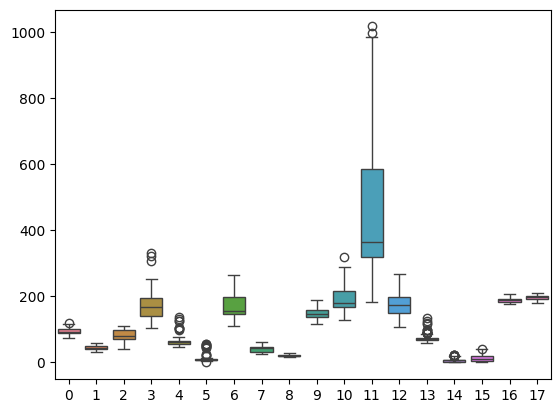

In [ ]:
sns.boxplot(data = df)

**see the distribution of the data and the result is  that data is imbalanced**

In [ ]:
df.iloc[: , -1].value_counts()

,count
18,
saab,243
bus,243
opel,232
van,222


**Visualizing the targets with other columns using histogram , scatter , box plots**

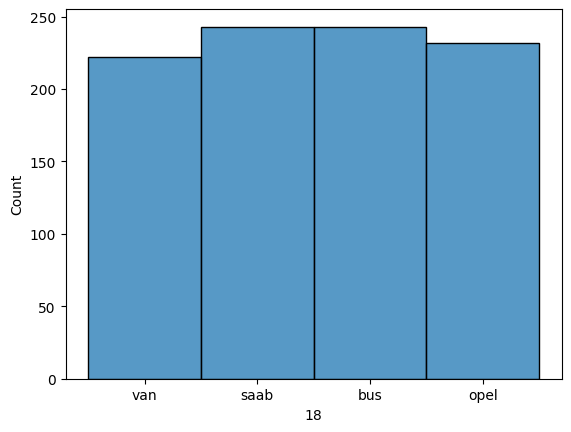

In [ ]:
sns.histplot(df.iloc[: , -1] )
plt.show()

<Axes: ylabel='18'>

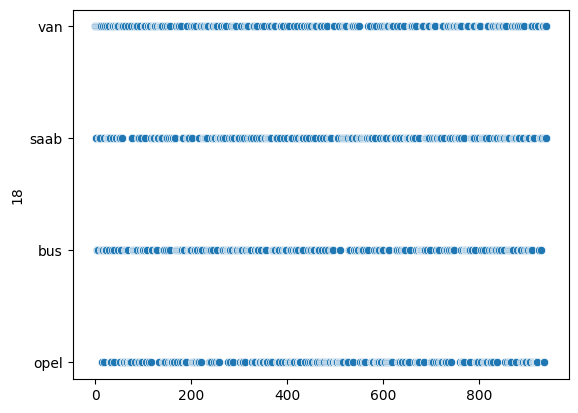

In [ ]:
sns.scatterplot(df.iloc[: , -1])

<Axes: ylabel='18'>

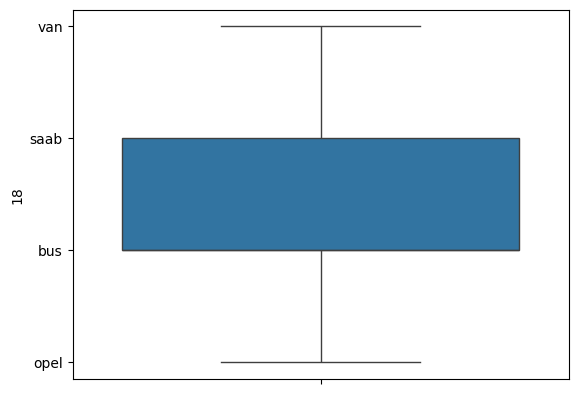

In [ ]:
sns.boxplot(df.iloc[: , -1])

In [ ]:
df.drop([18], axis = 1).corr()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
0,1.000000,0.693190,0.795162,0.691017,0.084140,0.131028,0.816214,-0.793244,0.815332,0.674300,0.765131,0.820830,0.583364,-0.250510,0.228907,0.173137,0.287709,0.355140
1,0.693190,1.000000,0.799182,0.622880,0.146011,0.233583,0.860173,-0.828900,0.857981,0.965576,0.808673,0.852169,0.934025,0.066839,0.158056,0.003441,-0.121436,0.028015
2,0.795162,0.799182,1.000000,0.769733,0.153732,0.248967,0.906276,-0.911488,0.894662,0.774155,0.862053,0.888363,0.703224,-0.227961,0.117811,0.269132,0.137486,0.322630
3,0.691017,0.622880,0.769733,1.000000,0.661335,0.439195,0.735864,-0.790782,0.708262,0.569290,0.794238,0.723039,0.535576,-0.185205,0.050601,0.178797,0.376841,0.464880
4,0.084140,0.146011,0.153732,0.661335,1.000000,0.644605,0.096467,-0.176536,0.069430,0.125951,0.263196,0.082824,0.118155,0.139357,-0.052791,-0.035602,0.246188,0.276274
5,0.131028,0.233583,0.248967,0.439195,0.644605,1.000000,0.150769,-0.164120,0.145433,0.291245,0.305722,0.129416,0.175605,0.289001,0.010769,0.039929,-0.020773,0.149305
6,0.816214,0.860173,0.906276,0.735864,0.096467,0.150769,1.000000,-0.973044,0.992176,0.809821,0.952405,0.996304,0.799800,-0.019276,0.079616,0.226105,-0.007457,0.104202
7,-0.793244,-0.828900,-0.911488,-0.790782,-0.176536,-0.164120,-0.973044,1.000000,-0.950293,-0.775029,-0.937932,-0.956022,-0.764309,0.098750,-0.060462,-0.196482,-0.102309,-0.202926
8,0.815332,0.857981,0.894662,0.708262,0.069430,0.145433,0.992176,-0.950293,1.000000,0.812542,0.939027,0.992318,0.797991,-0.006878,0.086441,0.229337,-0.034085,0.082740
9,0.674300,0.965576,0.774155,0.569290,0.125951,0.291245,0.809821,-0.775029,0.812542,1.000000,0.745889,0.796688,0.863793,0.048159,0.144641,0.020763,-0.116375,0.067238


**THERE IS NO MISSING VALUES THEN THERE IS NO NECESSARY OF USING IMPUTATION**

**using LabelEncoder to transform the catigorical column to numarical**

In [ ]:
from sklearn.preprocessing import LabelEncoder
label = {}
for col in df.select_dtypes(include = ['object']).columns:
  le = LabelEncoder()
  df[col] = le.fit_transform(df[col])
  label[col] = le
df

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
0,95,48,83,178,72,10,162,42,20,159,176,379,184,70,6,16,187,197,3
1,91,41,84,141,57,9,149,45,19,143,170,330,158,72,9,14,189,199,3
2,104,50,106,209,66,10,207,32,23,158,223,635,220,73,14,9,188,196,2
3,93,41,82,159,63,9,144,46,19,143,160,309,127,63,6,10,199,207,3
4,85,44,70,205,103,52,149,45,19,144,241,325,188,127,9,11,180,183,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
935,93,39,87,183,64,8,169,40,20,134,200,422,149,72,7,25,188,195,2
936,89,46,84,163,66,11,159,43,20,159,173,368,176,72,1,20,186,197,3
937,106,54,101,222,67,12,222,30,25,173,228,721,200,70,3,4,187,201,2
938,86,36,78,146,58,7,135,50,18,124,155,270,148,66,0,25,190,195,2


In [ ]:
df.corr()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
0,1.000000,0.693190,0.795162,0.691017,0.084140,0.131028,0.816214,-0.793244,0.815332,0.674300,0.765131,0.820830,0.583364,-0.250510,0.228907,0.173137,0.287709,0.355140,-0.007640
1,0.693190,1.000000,0.799182,0.622880,0.146011,0.233583,0.860173,-0.828900,0.857981,0.965576,0.808673,0.852169,0.934025,0.066839,0.158056,0.003441,-0.121436,0.028015,-0.173144
2,0.795162,0.799182,1.000000,0.769733,0.153732,0.248967,0.906276,-0.911488,0.894662,0.774155,0.862053,0.888363,0.703224,-0.227961,0.117811,0.269132,0.137486,0.322630,-0.061739
3,0.691017,0.622880,0.769733,1.000000,0.661335,0.439195,0.735864,-0.790782,0.708262,0.569290,0.794238,0.723039,0.535576,-0.185205,0.050601,0.178797,0.376841,0.464880,-0.171077
4,0.084140,0.146011,0.153732,0.661335,1.000000,0.644605,0.096467,-0.176536,0.069430,0.125951,0.263196,0.082824,0.118155,0.139357,-0.052791,-0.035602,0.246188,0.276274,-0.079336
5,0.131028,0.233583,0.248967,0.439195,0.644605,1.000000,0.150769,-0.164120,0.145433,0.291245,0.305722,0.129416,0.175605,0.289001,0.010769,0.039929,-0.020773,0.149305,0.207429
6,0.816214,0.860173,0.906276,0.735864,0.096467,0.150769,1.000000,-0.973044,0.992176,0.809821,0.952405,0.996304,0.799800,-0.019276,0.079616,0.226105,-0.007457,0.104202,-0.284501
7,-0.793244,-0.828900,-0.911488,-0.790782,-0.176536,-0.164120,-0.973044,1.000000,-0.950293,-0.775029,-0.937932,-0.956022,-0.764309,0.098750,-0.060462,-0.196482,-0.102309,-0.202926,0.328951
8,0.815332,0.857981,0.894662,0.708262,0.069430,0.145433,0.992176,-0.950293,1.000000,0.812542,0.939027,0.992318,0.797991,-0.006878,0.086441,0.229337,-0.034085,0.082740,-0.255023
9,0.674300,0.965576,0.774155,0.569290,0.125951,0.291245,0.809821,-0.775029,0.812542,1.000000,0.745889,0.796688,0.863793,0.048159,0.144641,0.020763,-0.116375,0.067238,-0.050425


***the features and target that will be predicted then splitting the data into training and testing sets***

In [ ]:
from sklearn.model_selection import train_test_split
x = df.iloc[: , : -1]
y = df.iloc[: , -1]
X_train , X_test , y_train , y_test = train_test_split(x , y , train_size = 0.8 , random_state = 0 , shuffle = True)
print(f'x_train shape = {X_train.shape}')
print(f'X_test shape = {X_test.shape}')
print(f'y_train shape = {y_train.shape}')
print(f'y_test shape = {y_test.shape}')


x_train shape = (752, 18)
X_test shape = (188, 18)
y_train shape = (752,)
y_test shape = (188,)


**Scal the data using Standerd Scaler**

In [ ]:
from sklearn.preprocessing import StandardScaler
scl = StandardScaler()
x_tr = scl.fit_transform(X_train)
x_ts = scl.transform(X_test)
scl

StandardScaler()

**using GridSearchCV to get the best parameters for each model like the value of C and the use of l2 or l1 regularization and the number of neighbors in KNN and so on**


In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
LG = LogisticRegression(class_weight = 'balanced')
esm1 = {'C':[0.001 , 0.01 , 0.1 , 1] , 'penalty' : ['l1 ' , 'l2']}
gr1 = GridSearchCV(LG , esm1).fit(X_train , y_train)
print(f'************************************************Best C and penalty is : {gr1.best_params_}***************************************************')


/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

************************************************Best C and penalty is : {'C': 0.1, 'penalty': 'l2'}***************************************************


/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
20 fits failed out of a total of 40.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
20 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.10/dist-packages/sklearn/base.py", line 1382, in wrapper
    estimator._validate_params()
  File "/usr/local/lib/python3.10/dist-packages/sklearn/base.py", line 436, in _validate_params
    validate_parameter_constraints(
  File "/usr/local/lib/python3.10/dist-packages/sklearn/utils/_

**using (class_weight)  in LogistcRegression model to balance the data and any changes happend to class_weight it affect directly on Visuals**

In [ ]:
from sklearn.metrics import accuracy_score , confusion_matrix , classification_report
M1 = LogisticRegression(class_weight = 'balanced' , C = 0.1 , penalty = 'l2').fit(X_train , y_train)# (the best value for C is 0.1 and penalty l2)
y_hat1 = M1.predict(X_test)
report = classification_report(y_test , y_hat1)
print(f'Model(1) coef = {M1.coef_}')
print(f'Model(1) score = {M1.score(X_test , y_test)}')
print(f'Model(1) Accuracy = {accuracy_score(y_test , y_hat1)}')
print(report)



Model(1) coef = [[-0.10488158 -0.00430989 -0.29450927 -0.01403877  0.17110744 -0.14874609
  -0.04462069 -0.08466514 -0.01519811 -0.10464443  0.07795943  0.03429304
   0.05097339  0.04852748 -0.10699425 -0.01785365  0.1441803  -0.07051628]
 [-0.11131677  0.00801817  0.02780869 -0.0044773  -0.10619352 -0.01556854
   0.03523557  0.06700158  0.00806894 -0.06541416 -0.02365434  0.02332201
   0.00213515 -0.03494891  0.03918989  0.03656811  0.03588719  0.03747101]
 [ 0.11095634 -0.04552651  0.06293833  0.00992129 -0.10578528 -0.00985713
   0.04974948  0.06513729  0.01609371 -0.1620913  -0.051068    0.01392358
   0.03989939 -0.0161729   0.06578373  0.03145378 -0.04126831  0.05590855]
 [ 0.10524201  0.04181823  0.20376225  0.00859479  0.04087136  0.17417177
  -0.04036436 -0.04747373 -0.00896454  0.33214989 -0.00323709 -0.07153863
  -0.09300793  0.00259433  0.00202064 -0.05016824 -0.13879918 -0.02286329]]
Model(1) score = 0.75
Model(1) Accuracy = 0.75
              precision    recall  f1-score 

/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


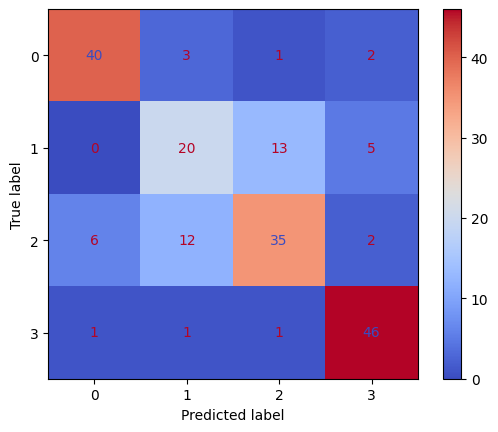

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test , y_hat1 , cmap = 'coolwarm')

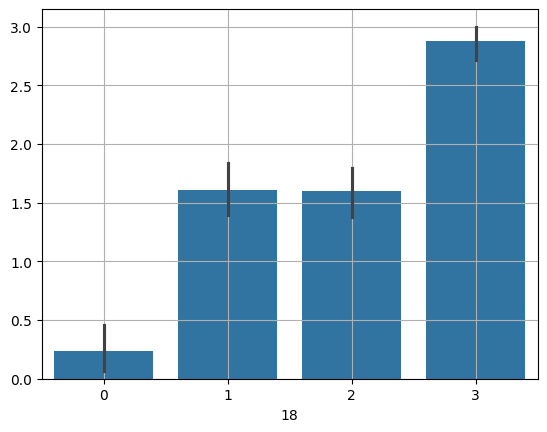

In [ ]:
sns.barplot(x = y_test , y = y_hat1 )
plt.grid(True)

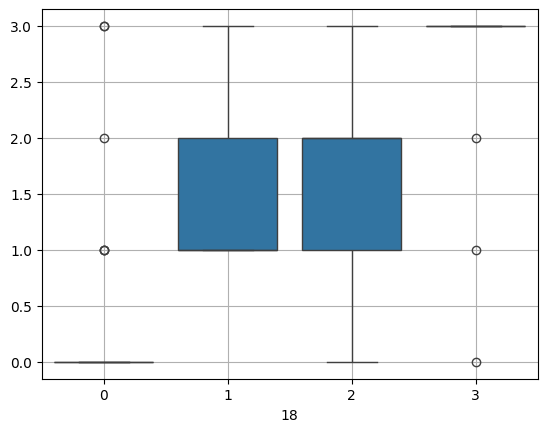

In [ ]:
sns.boxplot(x = y_test , y = y_hat1 )
plt.grid(True)

In [ ]:
from sklearn.linear_model import Lasso
ls = Lasso()
esm2 = {'alpha' : [0.001 , 0.01 , 0.1 , 1 , 2]}
gs2 =GridSearchCV(ls , esm2).fit(X_train , y_train)
print(f'************************************************Best Alpha Value For Lasso Model = {gs2.best_params_}***********************************************')

/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.432e+01, tolerance: 7.408e-02
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.043e+02, tolerance: 7.514e-02
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.053e+02, tolerance: 7.389e

************************************************Best Alpha Value For Lasso Model = {'alpha': 0.01}***********************************************


/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.412e+00, tolerance: 7.200e-02
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.289e+00, tolerance: 9.260e-02
  model = cd_fast.enet_coordinate_descent(


**using Lasso model and the changing in alpha value doesnt show any changes in Visualization**

In [ ]:
M2 = Lasso(alpha = 0.01).fit(X_train , y_train) # best alpha value is 0.01
y_hat2 = M1.predict(X_test)
print(f'Model(2) coef = {M2.coef_}')
print(f'Model(2) score = {M2.score(X_test , y_test)}')
print(f'Model(2) Accuracy = {accuracy_score(y_test , y_hat2)}')
report2 = classification_report(y_test , y_hat2)
print(report2)

Model(2) coef = [ 0.06316753 -0.21153303  0.05084882  0.01963594 -0.05978352  0.01699576
 -0.04670299  0.16726386  0.          0.07469869  0.00541731  0.00422363
  0.00731257  0.00679303  0.00707756 -0.01796166 -0.13226252  0.10416191]
Model(2) score = 0.6181625751753546
Model(2) Accuracy = 0.75
              precision    recall  f1-score   support

           0       0.85      0.87      0.86        46
           1       0.56      0.53      0.54        38
           2       0.70      0.64      0.67        55
           3       0.84      0.94      0.88        49

    accuracy                           0.75       188
   macro avg       0.74      0.74      0.74       188
weighted avg       0.74      0.75      0.75       188



/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.289e+00, tolerance: 9.260e-02
  model = cd_fast.enet_coordinate_descent(


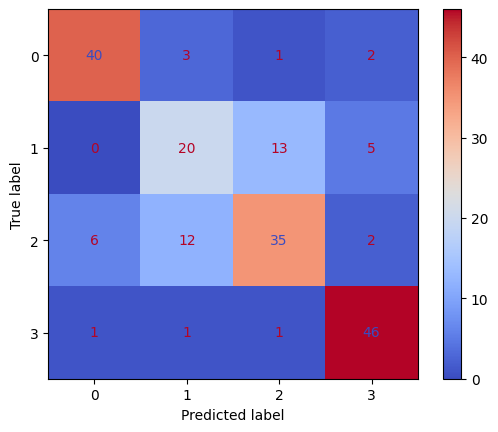

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_test , y_hat2 , cmap = 'coolwarm')

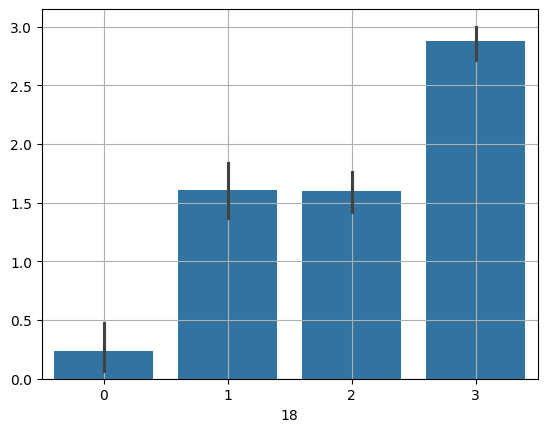

In [ ]:
sns.barplot(x = y_test , y = y_hat2)
plt.grid(True)

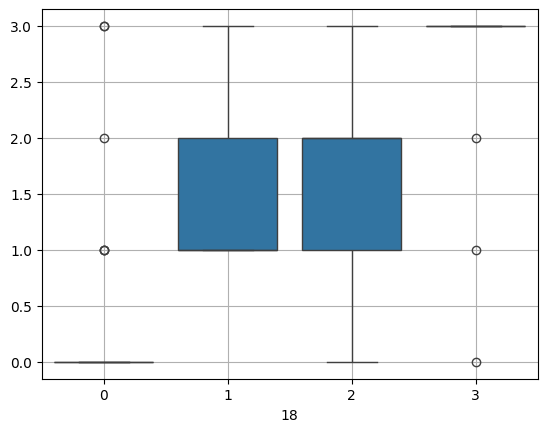

In [ ]:
sns.boxplot(x = y_test , y = y_hat2)
plt.grid(True)

In [ ]:
from sklearn.linear_model import Ridge
R = Ridge()
esm3 = {'alpha' : [10 , 5 , 1 , 0.1 , 0.01]}
gs3 = GridSearchCV(R , esm3).fit(X_train , y_train)
print(f'Best Alpha Value For Ridge Model = {gs3.best_params_}')

Best Alpha Value For Ridge Model = {'alpha': 10}


In [ ]:
from sklearn.metrics import mean_absolute_error , mean_squared_error
M3 = Ridge(alpha = 10).fit(X_train , y_train) # best alpha value is 10
y_hat3 = M3.predict(X_test)
#report3 = classification_report(y_test , y_hat3) //cant do report for ridge model
print(f'Model(3) score = {M3.score(X_test , y_test)}')
print(f'Model(3) MAE = {mean_absolute_error(y_test , y_hat3)}')
print(f'Model(3) MSE = {mean_squared_error(y_test , y_hat3)}')
print(f'Model(3) RMSE = {np.sqrt(mean_squared_error(y_test , y_hat3))}')

Model(3) score = 0.6128018490562515
Model(3) MAE = 0.5610912569173462
Model(3) MSE = 0.486265400801838
Model(3) RMSE = 0.6973273268715618


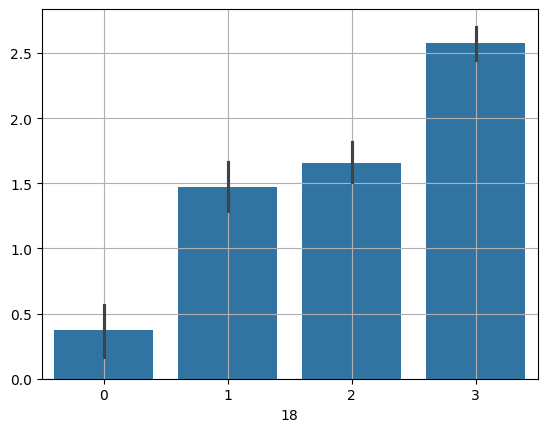

In [ ]:
sns.barplot(x = y_test ,y = y_hat3)
plt.grid(True)

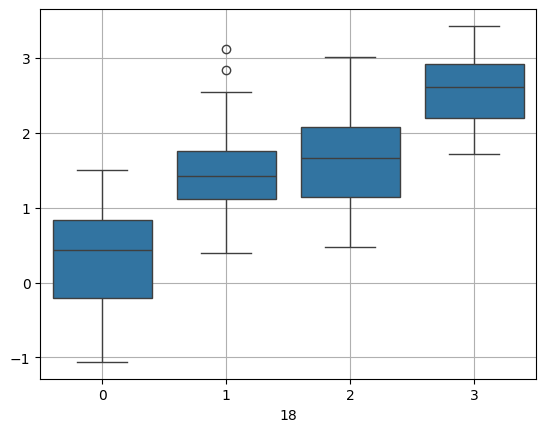

In [ ]:
sns.boxplot(x = y_test , y = y_hat3)
plt.grid(True)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
KNN = KNeighborsClassifier()
esm4 = {'n_neighbors' : [1 , 3 , 5 , 6 , 7 , 10]}
gs4 = GridSearchCV(KNN , esm4).fit(X_train , y_train)
print(f'Best Number Of Neighbors is = {gs4.best_params_}')

Best Number Of Neighbors is = {'n_neighbors': 1}


In [ ]:
M4 = KNeighborsClassifier(n_neighbors = 1).fit(X_train , y_train) # best n_neighbors is 1
y_hat4 = M4.predict(X_test)
report4 = classification_report(y_test , y_hat4)
print(f'Model(4) Score = {M4.score(X_test , y_test)}')
print(f'Model(4) Accuracy = {accuracy_score(y_test , y_hat4)}')
print(report4)

Model(4) Score = 0.7021276595744681
Model(4) Accuracy = 0.7021276595744681
              precision    recall  f1-score   support

           0       0.85      0.89      0.87        46
           1       0.39      0.37      0.38        38
           2       0.56      0.53      0.54        55
           3       0.92      0.98      0.95        49

    accuracy                           0.70       188
   macro avg       0.68      0.69      0.69       188
weighted avg       0.69      0.70      0.70       188



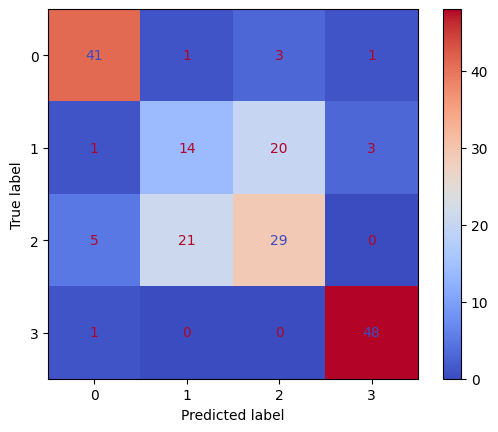

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_test , y_hat4 , cmap = 'coolwarm')

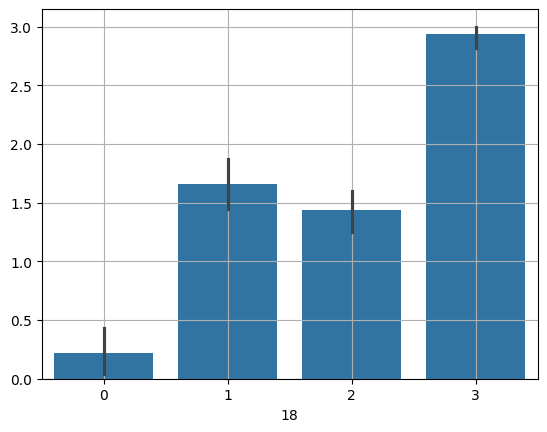

In [ ]:
sns.barplot(x = y_test , y = y_hat4 )
plt.grid(True)

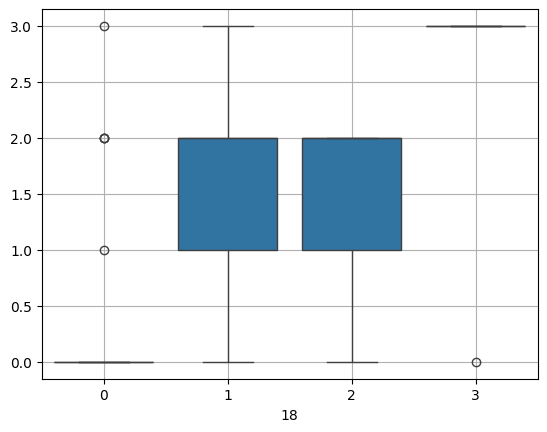

In [ ]:
sns.boxplot(x = y_test , y = y_hat4)
plt.grid(True)

In [ ]:
from sklearn.svm import SVC
SV = SVC()
esm5 = {'C' : [ 1 , 3 , 5 , 7 , 10 , 15] , 'kernel' : ['linear' , 'boly' , 'rbf']}
gs5 = GridSearchCV(SV , esm5).fit(X_train , y_train)
print(f'****************************************Best Value Of C And Kernel In SVC Model = {gs5.best_params_}*******************************************')

/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
30 fits failed out of a total of 90.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
30 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.10/dist-packages/sklearn/base.py", line 1382, in wrapper
    estimator._validate_params()
  File "/usr/local/lib/python3.10/dist-packages/sklearn/base.py", line 436, in _validate_params
    validate_parameter_constraints(
  File "/usr/local/lib/python3.10/dist-packages/sklearn/utils/_

****************************************Best Value Of C And Kernel In SVC Model = {'C': 1, 'kernel': 'linear'}*******************************************


In [ ]:
M5 = SVC(C = 1 , kernel = 'linear').fit(X_train , y_train) # best C value is 1
y_hat5 = M5.predict(X_test)
report5 = classification_report(y_test , y_hat5)
print(f'Model(5) Score = {M5.score(X_test , y_test)}')
print(f'Model(5) Accuracy = {accuracy_score(y_test , y_hat5)}')
print(report5)

Model(5) Score = 0.8138297872340425
Model(5) Accuracy = 0.8138297872340425
              precision    recall  f1-score   support

           0       0.91      0.91      0.91        46
           1       0.66      0.66      0.66        38
           2       0.69      0.69      0.69        55
           3       0.98      0.98      0.98        49

    accuracy                           0.81       188
   macro avg       0.81      0.81      0.81       188
weighted avg       0.81      0.81      0.81       188



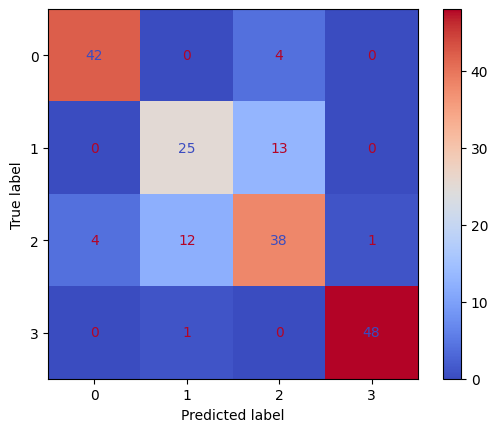

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_test , y_hat5 , cmap = 'coolwarm')

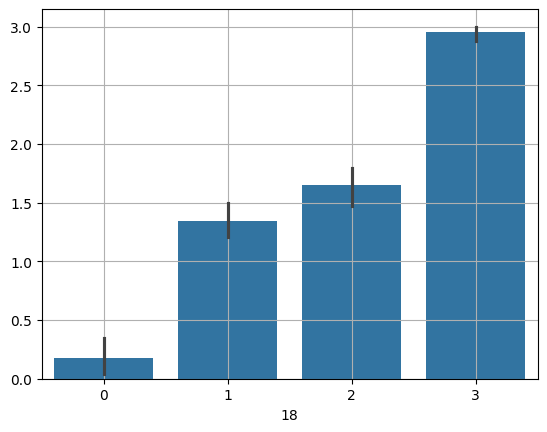

In [ ]:
sns.barplot(x = y_test , y = y_hat5)
plt.grid(True)

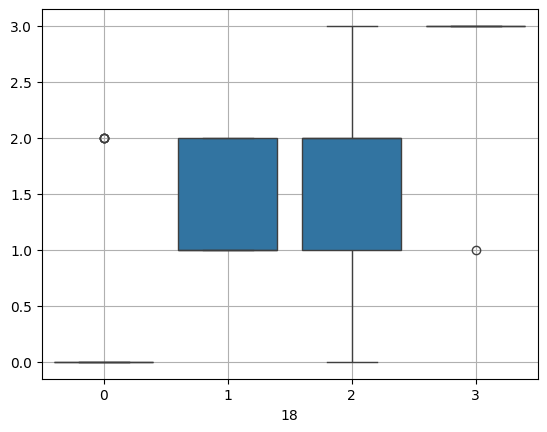

In [ ]:
sns.boxplot(x = y_test , y = y_hat5)
plt.grid(True)

In [ ]:
from sklearn.tree import DecisionTreeClassifier
DT = DecisionTreeClassifier()
esm6 = {'max_depth' : [1 , 3 , 5 , 6 , 7]}
gs6 = GridSearchCV(DT , esm6).fit(X_train , y_train)
print(f'Best max Depth For Decisiom tree is = {gs6.best_params_}')

Best max Depth For Decisiom tree is = {'max_depth': 7}


In [ ]:
M6 = DecisionTreeClassifier(max_depth = 7).fit(X_train , y_train) # best value for max_depth is 7
y_hat6 = M6.predict(X_test)
report6 = classification_report(y_test , y_hat6)
print(f'Model(6) Score =  {M6.score(X_test , y_test)}')
print(f'Model(6) Accuracy = {accuracy_score(y_test , y_hat6)}')
print(report6)

Model(6) Score =  0.7074468085106383
Model(6) Accuracy = 0.7074468085106383
              precision    recall  f1-score   support

           0       0.84      0.89      0.86        46
           1       0.50      0.50      0.50        38
           2       0.59      0.55      0.57        55
           3       0.86      0.88      0.87        49

    accuracy                           0.71       188
   macro avg       0.70      0.70      0.70       188
weighted avg       0.70      0.71      0.70       188



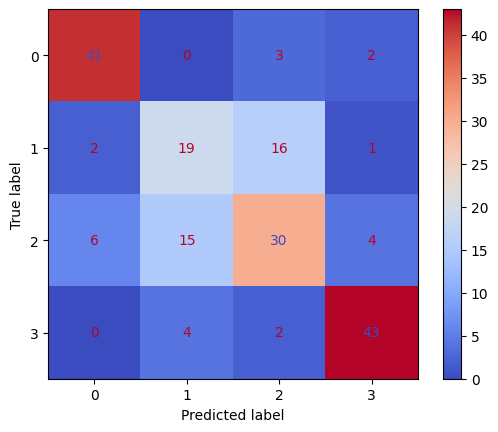

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_test , y_hat6 , cmap = 'coolwarm')

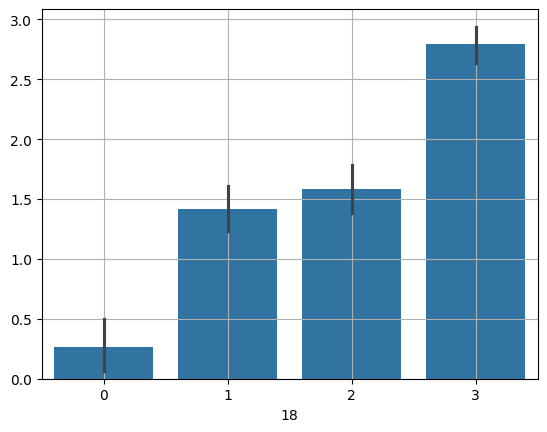

In [ ]:
sns.barplot(x = y_test , y = y_hat6)
plt.grid(True)

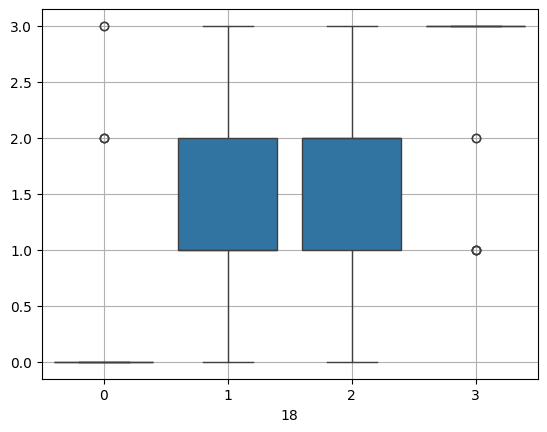

In [ ]:
sns.boxplot(x = y_test , y = y_hat6)
plt.grid(True)

In [ ]:
from sklearn.ensemble import RandomForestClassifier
RF = RandomForestClassifier()
esm7 = {'max_depth' : [1 , 3 , 5 , 6 , 7] , 'n_estimators' : [50 , 100 , 200 , 300 , 400]}
gs7 = GridSearchCV(RF , esm7).fit(X_train , y_train)
print(f'Best Max Depth And Number Of Estimators For Random Forest Model is = {gs7.best_params_}')

Best Max Depth And Number Of Estimators For Random Forest Model is = {'max_depth': 7, 'n_estimators': 400}


In [ ]:
M7 = RandomForestClassifier(max_depth = 7 , n_estimators = 400).fit(X_train , y_train) # best max_depth is 7 and n_estimators is 400
y_hat7 = M7.predict(X_test)
report7 = classification_report(y_test , y_hat7)
print(f'Model(7) Score = {M7.score(X_test , y_test)}')
print(f'Model(7) Accuracy = {accuracy_score(y_test , y_hat7)}')
print(report)

Model(7) Score = 0.7978723404255319
Model(7) Accuracy = 0.7978723404255319
              precision    recall  f1-score   support

           0       0.85      0.87      0.86        46
           1       0.56      0.53      0.54        38
           2       0.70      0.64      0.67        55
           3       0.84      0.94      0.88        49

    accuracy                           0.75       188
   macro avg       0.74      0.74      0.74       188
weighted avg       0.74      0.75      0.75       188



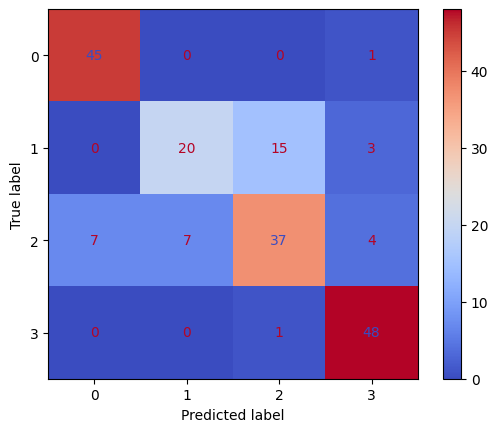

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_test , y_hat7 , cmap = 'coolwarm')

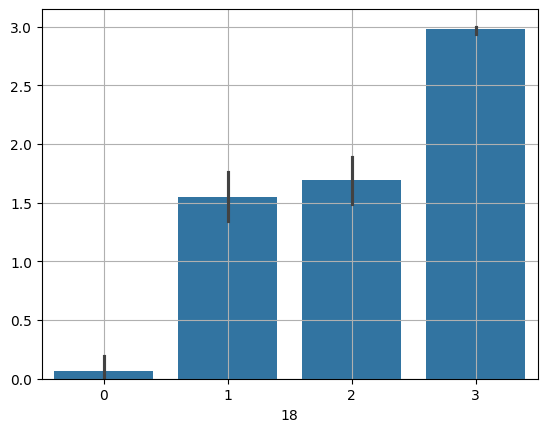

In [ ]:
sns.barplot(x = y_test , y = y_hat7)
plt.grid(True)

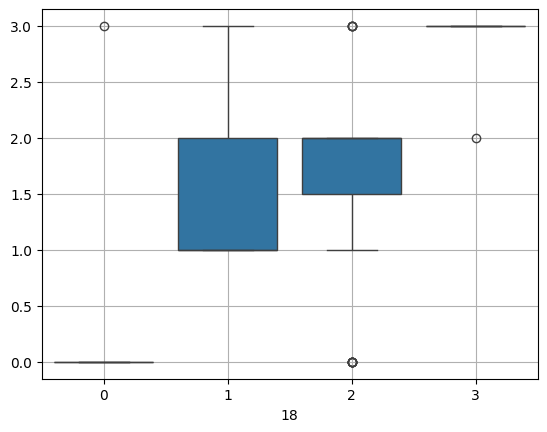

In [ ]:
sns.boxplot(x = y_test , y = y_hat7)
plt.grid(True)

**Extra Credit (1) Using t Recursive Feature Elimination (RFE)**

In [ ]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
LG2 = LogisticRegression()
RF = RFE(LG2 , n_features_to_select = 10).fit(X_train , y_train)
print(RF.ranking_ , '*****************************************************************')
print(RF.score(X_test , y_test))

/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

[1 7 1 8 1 1 1 3 9 1 1 6 2 4 1 5 1 1] *****************************************************************
0.7606382978723404


/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c